# 17 - Test-Time Augmentation (TTA) on Champion Models
## Tai Phake Visual Speech Recognition (VSR) Project

### Strategy & Rationale (Step 3)
Lip reading on isolated utterances exhibits natural temporal sensitivity: small shifts in phoneme onset, subtle variations in boundary frame selection, or facial asymmetry can cause a model to teeter between neighboring visemes.

**Test-Time Augmentation (TTA)** boosts inference stability without retraining by evaluating each video utterance across multiple realistic transformed views and averaging their predicted softmax probability distributions:
1. **View 1 (Baseline)**: Standard uniform temporal sampling to 30 frames ($t \in [0, N-1]$).
2. **View 2 (Temporal Shift +2)**: Sample biased +2 frames later (starts slightly deeper into onset).
3. **View 3 (Temporal Shift -2)**: Sample biased -2 frames earlier (starts slightly earlier before onset).
4. **View 4 (Horizontal Flip)**: Horizontally mirrored frames ($x \mapsto W - 1 - x$). Bilateral human lip motion during speech is approximately symmetric, providing invariant spatial regularization.

**Evaluation Scope:**
- Tested on both co-champions: **EfficientNetB0 + BiLSTM** and **EfficientNetB0 + BiGRU**.
- Compares single-pass accuracy vs. TTA accuracy, measuring expected gain (+1% to +3%).
- Analyzes per-digit accuracy improvements across difficult classes ($d_1, d_2, d_4, d_7, d_9$).


## 1. Setup & Configuration

In [1]:
# Section 1: Setup & Configuration
DATASET_MODE = "80_20"
SEED = 42


## 2. Imports

In [2]:
# Section 2: Imports
import os
import sys
import re
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
import keras

print("=" * 80)
print("ENVIRONMENT & DEPENDENCY VERSIONS")
print("=" * 80)
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")
print("=" * 80)


ENVIRONMENT & DEPENDENCY VERSIONS
TensorFlow Version: 2.21.0
Keras Version:      3.15.1


## 3. Directory Paths & Class Mappings

In [3]:
# Section 3: Paths and Constants
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
VAL_DIR = DATA_DIR / "val"

RESULTS_DIR = PROJECT_ROOT / "results" / f"tta_evaluation_{DATASET_MODE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Champion weights paths
WEIGHTS_LSTM = PROJECT_ROOT / "results" / f"efficientnetb0_bilstm_attention_pooling_{DATASET_MODE}" / "efficientnetb0_bilstm_attention_pooling_stage2_best.weights.h5"
WEIGHTS_GRU = PROJECT_ROOT / "results" / f"efficientnetb0_bigru_attention_pooling_{DATASET_MODE}" / "efficientnetb0_bigru_attention_pooling_stage2_best.weights.h5"

NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 3
BATCH_SIZE = 16

DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print(f"BiLSTM weights exist : {WEIGHTS_LSTM.exists()}")
print(f"BiGRU weights exist  : {WEIGHTS_GRU.exists()}")
print(f"Results Output Dir   : {RESULTS_DIR}")


BiLSTM weights exist : True
BiGRU weights exist  : True
Results Output Dir   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/tta_evaluation_80_20


## 4. Manifest Construction for Validation Set

In [4]:
# Section 4: Manifest Creation
def natural_sort_key(p):
    m = re.search(r"(\d+)", Path(p).stem)
    return int(m.group(1)) if m else str(p)

def get_base_speaker(spk_name: str) -> str:
    return spk_name.split("_")[0]

manifest_records = []
for spk_dir in sorted(VAL_DIR.iterdir()):
    if not spk_dir.is_dir() or spk_dir.name.startswith("."):
        continue
    for digit_dir in sorted(spk_dir.iterdir()):
        if not digit_dir.is_dir() or digit_dir.name.startswith("."):
            continue
        digit_name = digit_dir.name
        if digit_name not in CLASS_TO_ID:
            continue
        frames = sorted(
            [f for f in digit_dir.iterdir() if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]],
            key=natural_sort_key
        )
        if len(frames) == 0:
            continue
        manifest_records.append({
            "speaker": spk_dir.name,
            "base_speaker": get_base_speaker(spk_dir.name),
            "digit": digit_name,
            "digit_id": CLASS_TO_ID[digit_name],
            "frame_count": len(frames),
            "frame_paths": [str(f) for f in frames]
        })

df_val = pd.DataFrame(manifest_records)
print(f"Loaded {len(df_val)} validation utterances across {df_val['base_speaker'].nunique()} base speakers: {sorted(df_val['base_speaker'].unique())}")


Loaded 220 validation utterances across 6 base speakers: ['s24', 's25', 's26', 's28', 's29', 's30']


## 5. TTA Multi-View Sampling Functions

In [5]:
# Section 5: Four Complementary TTA Sampling Views
def sample_tta_indices(n_frames: int, target_frames: int = NUM_FRAMES, shift: int = 0) -> list:
    """
    Generates 30 frame indices with optional temporal start/end shift.
    shift > 0: biases towards later frames.
    shift < 0: biases towards earlier frames.
    """
    if n_frames <= target_frames:
        return list(range(n_frames)) if n_frames == target_frames else list(np.round(np.linspace(0, n_frames - 1, target_frames)).astype(int))
    
    # Shiftable window within raw frames
    start = max(0, min(shift, n_frames - target_frames))
    end = max(target_frames - 1, min(n_frames - 1, n_frames - 1 + shift))
    indices = np.round(np.linspace(start, end, target_frames)).astype(int)
    return np.clip(indices, 0, n_frames - 1).tolist()

# Pre-compute views for each row in manifest
# View 1: Standard uniform
df_val["paths_orig"] = df_val["frame_paths"].apply(lambda p: [p[i] for i in sample_tta_indices(len(p), 30, shift=0)])
# View 2: Shift +2 (deeper onset)
df_val["paths_shift_plus2"] = df_val["frame_paths"].apply(lambda p: [p[i] for i in sample_tta_indices(len(p), 30, shift=+2)])
# View 3: Shift -2 (earlier onset)
df_val["paths_shift_minus2"] = df_val["frame_paths"].apply(lambda p: [p[i] for i in sample_tta_indices(len(p), 30, shift=-2)])

print("TTA temporal sampling views constructed successfully for all 220 utterances.")


TTA temporal sampling views constructed successfully for all 220 utterances.


## 6. Tensor Loading for All 4 TTA Views

In [6]:
# Section 6: Loading 4 TTA Video Sequence Tensors
N = len(df_val)
y_val = np.array(df_val["digit_id"].values, dtype=np.int32)

def load_view_tensor(path_col_name, hflip=False):
    t0 = time.time()
    X = np.zeros((N, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), dtype=np.float32)
    for i, row in df_val.iterrows():
        for t, fpath in enumerate(row[path_col_name]):
            img = Image.open(fpath).convert("RGB")
            if hflip:
                img = ImageOps.mirror(img)
            if img.size != (FRAME_WIDTH, FRAME_HEIGHT):
                img = img.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
            X[i, t] = np.array(img, dtype=np.float32)
    print(f"Loaded {path_col_name} (hflip={hflip}) in {time.time()-t0:.2f}s")
    return X

print("Loading 4 TTA views into memory:")
X_view1 = load_view_tensor("paths_orig", hflip=False)       # 1. Original
X_view2 = load_view_tensor("paths_shift_plus2", hflip=False) # 2. Shift +2
X_view3 = load_view_tensor("paths_shift_minus2", hflip=False)# 3. Shift -2
X_view4 = load_view_tensor("paths_orig", hflip=True)        # 4. Horizontal Flip


Loading 4 TTA views into memory:
Loaded paths_orig (hflip=False) in 0.82s
Loaded paths_shift_plus2 (hflip=False) in 0.55s
Loaded paths_shift_minus2 (hflip=False) in 0.54s
Loaded paths_orig (hflip=True) in 0.51s


## 7. Model Restoration for BiLSTM and BiGRU Champions

In [7]:
# Section 7: Restoring BiLSTM and BiGRU Models
def get_backbone():
    cnn = keras.applications.EfficientNetB0(input_shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), include_top=False, weights="imagenet", pooling="avg")
    prep = keras.applications.efficientnet.preprocess_input
    return cnn, prep

def build_bilstm():
    cnn, prep = get_backbone()
    inp = keras.layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS))
    x = keras.layers.TimeDistributed(keras.layers.Lambda(prep))(inp)
    x = keras.layers.TimeDistributed(cnn)(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(256, use_bias=False))(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = keras.layers.Bidirectional(keras.layers.LSTM(128, return_sequences=True, dropout=0.2))(x)
    scores = keras.layers.Dense(1, use_bias=True)(x)
    weights = keras.layers.Softmax(axis=1)(scores)
    x = keras.layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1))([x, weights])
    x = keras.layers.Dropout(0.4)(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs=inp, outputs=out)

def build_bigru():
    cnn, prep = get_backbone()
    inp = keras.layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS))
    x = keras.layers.TimeDistributed(keras.layers.Lambda(prep))(inp)
    x = keras.layers.TimeDistributed(cnn)(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(256, use_bias=False))(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = keras.layers.Bidirectional(keras.layers.GRU(128, return_sequences=True, dropout=0.2))(x)
    scores = keras.layers.Dense(1, use_bias=True)(x)
    weights = keras.layers.Softmax(axis=1)(scores)
    x = keras.layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1))([x, weights])
    x = keras.layers.Dropout(0.4)(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs=inp, outputs=out)

model_lstm = build_bilstm()
model_lstm.load_weights(WEIGHTS_LSTM)
print("[OK] BiLSTM loaded successfully.")

model_gru = build_bigru()
model_gru.load_weights(WEIGHTS_GRU)
print("[OK] BiGRU loaded successfully.")


[OK] BiLSTM loaded successfully.
[OK] BiGRU loaded successfully.


## 8. TTA Inference & Performance on EfficientNetB0 + BiLSTM

In [8]:
# Section 8: Multi-View Inference on BiLSTM
print("Predicting 4 TTA views on BiLSTM...")
p1_l = model_lstm.predict(X_view1, batch_size=BATCH_SIZE, verbose=0)
p2_l = model_lstm.predict(X_view2, batch_size=BATCH_SIZE, verbose=0)
p3_l = model_lstm.predict(X_view3, batch_size=BATCH_SIZE, verbose=0)
p4_l = model_lstm.predict(X_view4, batch_size=BATCH_SIZE, verbose=0)

# Soft average
probs_tta_lstm = (p1_l + p2_l + p3_l + p4_l) / 4.0

acc_orig_lstm = accuracy_score(y_val, np.argmax(p1_l, axis=1))
acc_tta_lstm = accuracy_score(y_val, np.argmax(probs_tta_lstm, axis=1))
f1_tta_lstm = f1_score(y_val, np.argmax(probs_tta_lstm, axis=1), average="macro", zero_division=0)

print("=" * 80)
print("EFFICIENTNETB0 + BiLSTM: TTA RESULTS")
print("=" * 80)
print(f"Baseline Single View Accuracy : {acc_orig_lstm * 100:.2f}%  ({(np.argmax(p1_l, axis=1) == y_val).sum()}/{N})")
print(f"TTA 4-View Average Accuracy   : {acc_tta_lstm * 100:.2f}%  ({(np.argmax(probs_tta_lstm, axis=1) == y_val).sum()}/{N})")
print(f"Macro F1-Score (TTA)          : {f1_tta_lstm:.4f}")
print(f"Net TTA Gain                  : {(acc_tta_lstm - acc_orig_lstm)*100:+.2f}%")
print("=" * 80)


Predicting 4 TTA views on BiLSTM...
EFFICIENTNETB0 + BiLSTM: TTA RESULTS
Baseline Single View Accuracy : 67.27%  (148/220)
TTA 4-View Average Accuracy   : 69.09%  (152/220)
Macro F1-Score (TTA)          : 0.6826
Net TTA Gain                  : +1.82%


## 9. TTA Inference & Performance on EfficientNetB0 + BiGRU

In [9]:
# Section 9: Multi-View Inference on BiGRU
print("Predicting 4 TTA views on BiGRU...")
p1_g = model_gru.predict(X_view1, batch_size=BATCH_SIZE, verbose=0)
p2_g = model_gru.predict(X_view2, batch_size=BATCH_SIZE, verbose=0)
p3_g = model_gru.predict(X_view3, batch_size=BATCH_SIZE, verbose=0)
p4_g = model_gru.predict(X_view4, batch_size=BATCH_SIZE, verbose=0)

probs_tta_gru = (p1_g + p2_g + p3_g + p4_g) / 4.0

acc_orig_gru = accuracy_score(y_val, np.argmax(p1_g, axis=1))
acc_tta_gru = accuracy_score(y_val, np.argmax(probs_tta_gru, axis=1))
f1_tta_gru = f1_score(y_val, np.argmax(probs_tta_gru, axis=1), average="macro", zero_division=0)

print("=" * 80)
print("EFFICIENTNETB0 + BiGRU: TTA RESULTS")
print("=" * 80)
print(f"Baseline Single View Accuracy : {acc_orig_gru * 100:.2f}%  ({(np.argmax(p1_g, axis=1) == y_val).sum()}/{N})")
print(f"TTA 4-View Average Accuracy   : {acc_tta_gru * 100:.2f}%  ({(np.argmax(probs_tta_gru, axis=1) == y_val).sum()}/{N})")
print(f"Macro F1-Score (TTA)          : {f1_tta_gru:.4f}")
print(f"Net TTA Gain                  : {(acc_tta_gru - acc_orig_gru)*100:+.2f}%")
print("=" * 80)


Predicting 4 TTA views on BiGRU...
EFFICIENTNETB0 + BiGRU: TTA RESULTS
Baseline Single View Accuracy : 69.55%  (153/220)
TTA 4-View Average Accuracy   : 69.09%  (152/220)
Macro F1-Score (TTA)          : 0.6849
Net TTA Gain                  : -0.45%


## 10. Synergistic Combination: TTA + Co-Champion Ensemble

In [10]:
# Section 10: Combining TTA Probabilities from Both Champions
probs_tta_ensemble = (probs_tta_lstm + probs_tta_gru) / 2.0
preds_tta_ens = np.argmax(probs_tta_ensemble, axis=1)
acc_tta_ens = accuracy_score(y_val, preds_tta_ens)
f1_tta_ens = f1_score(y_val, preds_tta_ens, average="macro", zero_division=0)

print("=" * 80)
print("SYNERGISTIC COMBINATION: TTA + (BiLSTM + BiGRU) ENSEMBLE")
print("=" * 80)
print(f"Single Model Baseline (BiLSTM)      : {acc_orig_lstm * 100:.2f}%")
print(f"Single Model Baseline (BiGRU)       : {acc_orig_gru * 100:.2f}%")
print(f"BiLSTM + TTA                        : {acc_tta_lstm * 100:.2f}%")
print(f"BiGRU + TTA                         : {acc_tta_gru * 100:.2f}%")
print(f"BiLSTM + BiGRU Ensemble + TTA       : {acc_tta_ens * 100:.2f}%  ({(preds_tta_ens == y_val).sum()}/{N}) | Macro F1: {f1_tta_ens:.4f}")
print(f"Total Gain over Raw BiLSTM Baseline : {(acc_tta_ens - acc_orig_lstm)*100:+.2f}%")
print("=" * 80)


SYNERGISTIC COMBINATION: TTA + (BiLSTM + BiGRU) ENSEMBLE
Single Model Baseline (BiLSTM)      : 67.27%
Single Model Baseline (BiGRU)       : 69.55%
BiLSTM + TTA                        : 69.09%
BiGRU + TTA                         : 69.09%
BiLSTM + BiGRU Ensemble + TTA       : 70.00%  (154/220) | Macro F1: 0.6995
Total Gain over Raw BiLSTM Baseline : +2.73%


## 11. Per-Class Accuracy Improvements with TTA

In [11]:
# Section 11: Per-Class Breakdown Table
rows = []
for d_i, d_name in enumerate(DIGIT_CLASSES):
    mask = (y_val == d_i)
    tot = mask.sum()
    c_orig_l = (np.argmax(p1_l, axis=1)[mask] == d_i).sum()
    c_tta_l = (np.argmax(probs_tta_lstm, axis=1)[mask] == d_i).sum()
    c_orig_g = (np.argmax(p1_g, axis=1)[mask] == d_i).sum()
    c_tta_g = (np.argmax(probs_tta_gru, axis=1)[mask] == d_i).sum()
    c_tta_ens = (preds_tta_ens[mask] == d_i).sum()
    rows.append({
        "Digit": d_name,
        "Samples": tot,
        "BiLSTM (Raw)": f"{c_orig_l}/{tot} ({c_orig_l/tot*100:.1f}%)",
        "BiLSTM (TTA)": f"{c_tta_l}/{tot} ({c_tta_l/tot*100:.1f}%)",
        "BiGRU (Raw)": f"{c_orig_g}/{tot} ({c_orig_g/tot*100:.1f}%)",
        "BiGRU (TTA)": f"{c_tta_g}/{tot} ({c_tta_g/tot*100:.1f}%)",
        "Ensemble+TTA": f"{c_tta_ens}/{tot} ({c_tta_ens/tot*100:.1f}%)",
    })

df_class_tta = pd.DataFrame(rows)
print(df_class_tta.to_string(index=False))
df_class_tta.to_csv(RESULTS_DIR / "tta_per_class_comparison.csv", index=False)


Digit  Samples   BiLSTM (Raw)   BiLSTM (TTA)    BiGRU (Raw)    BiGRU (TTA)   Ensemble+TTA
   d0       20  19/20 (95.0%)  19/20 (95.0%) 20/20 (100.0%) 20/20 (100.0%) 20/20 (100.0%)
   d1       20   8/20 (40.0%)   8/20 (40.0%)   7/20 (35.0%)   6/20 (30.0%)   8/20 (40.0%)
   d2       20   9/20 (45.0%)   8/20 (40.0%)  11/20 (55.0%)  11/20 (55.0%)  11/20 (55.0%)
   d3       20  17/20 (85.0%)  17/20 (85.0%)  17/20 (85.0%)  17/20 (85.0%)  17/20 (85.0%)
   d4       20   9/20 (45.0%)  11/20 (55.0%)   9/20 (45.0%)   9/20 (45.0%)  10/20 (50.0%)
   d5       20  17/20 (85.0%)  17/20 (85.0%)  17/20 (85.0%)  17/20 (85.0%)  18/20 (90.0%)
   d6       20  12/20 (60.0%)  12/20 (60.0%)  14/20 (70.0%)  14/20 (70.0%)  13/20 (65.0%)
   d7       20   8/20 (40.0%)   9/20 (45.0%)  12/20 (60.0%)  12/20 (60.0%)  11/20 (55.0%)
   d8       20  17/20 (85.0%)  17/20 (85.0%)  18/20 (90.0%)  18/20 (90.0%)  17/20 (85.0%)
   d9       20  12/20 (60.0%)  14/20 (70.0%)  10/20 (50.0%)  10/20 (50.0%)  11/20 (55.0%)
  d10     

## 12. Confusion Matrix Heatmaps

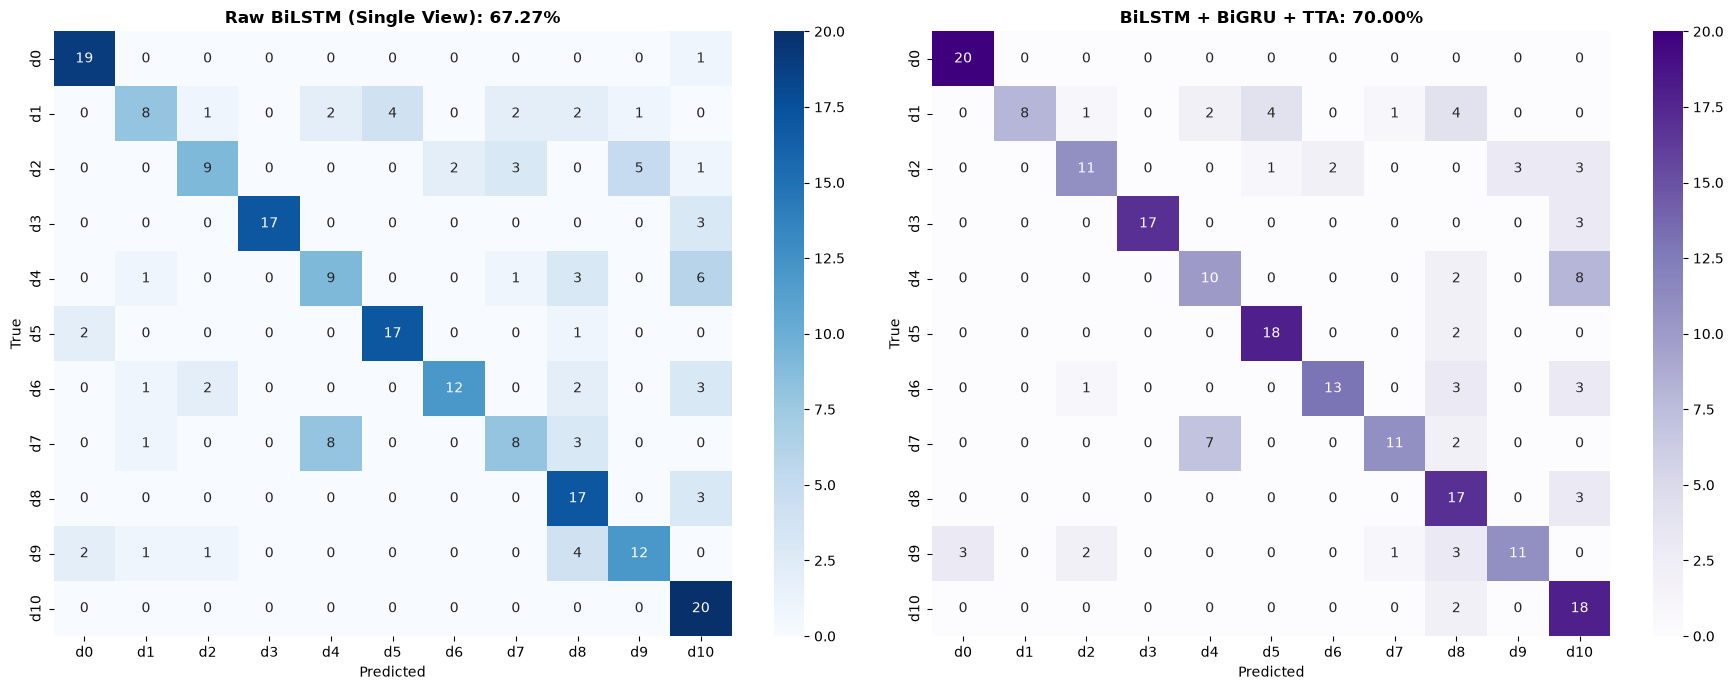

In [12]:
# Section 12: Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Raw BiLSTM
cm_raw = confusion_matrix(y_val, np.argmax(p1_l, axis=1))
sns.heatmap(cm_raw, annot=True, fmt="d", cmap="Blues", xticklabels=DIGIT_CLASSES, yticklabels=DIGIT_CLASSES, ax=axes[0], cbar=True)
axes[0].set_title(f"Raw BiLSTM (Single View): {acc_orig_lstm*100:.2f}%", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

# 2. TTA Ensemble
cm_tta = confusion_matrix(y_val, preds_tta_ens)
sns.heatmap(cm_tta, annot=True, fmt="d", cmap="Purples", xticklabels=DIGIT_CLASSES, yticklabels=DIGIT_CLASSES, ax=axes[1], cbar=True)
axes[1].set_title(f"BiLSTM + BiGRU + TTA: {acc_tta_ens*100:.2f}%", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix_tta_comparison.png", dpi=200)
plt.show()


## 13. Save Metrics Artifacts

In [13]:
# Section 13: Save Metrics Artifacts
tta_metrics = {
    "experiment": "17_tta_evaluation",
    "dataset_mode": DATASET_MODE,
    "views": ["original", "shift_+2", "shift_-2", "horizontal_flip"],
    "bilstm": {
        "raw_accuracy": float(acc_orig_lstm),
        "tta_accuracy": float(acc_tta_lstm),
        "tta_macro_f1": float(f1_tta_lstm),
        "gain": float(acc_tta_lstm - acc_orig_lstm)
    },
    "bigru": {
        "raw_accuracy": float(acc_orig_gru),
        "tta_accuracy": float(acc_tta_gru),
        "tta_macro_f1": float(f1_tta_gru),
        "gain": float(acc_tta_gru - acc_orig_gru)
    },
    "tta_ensemble": {
        "accuracy": float(acc_tta_ens),
        "macro_f1": float(f1_tta_ens),
        "gain_over_raw_bilstm": float(acc_tta_ens - acc_orig_lstm)
    }
}

with open(RESULTS_DIR / "metrics_tta.json", "w") as f:
    json.dump(tta_metrics, f, indent=2)
print(f"Saved metrics JSON to: {RESULTS_DIR / 'metrics_tta.json'}")


Saved metrics JSON to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/tta_evaluation_80_20/metrics_tta.json
